Saving images.jpg to images.jpg


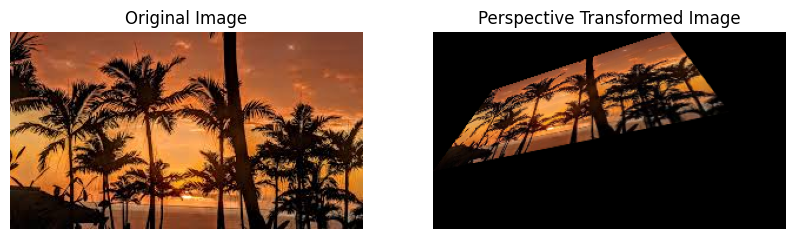

In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
img = cv2.imread(filename)

if img is None:
    print("Unable to read image")
else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]

    src = np.float32([
        [0, 0],
        [w-1, 0],
        [0, h-1],
        [w-1, h-1]
    ])

    dst = np.float32([
        [50, 50],
        [w-100, 0],
        [0, h-50],
        [w-50, h-100]
    ])

    matrix = cv2.getPerspectiveTransform(src, dst)
    result = cv2.warpPerspective(img, matrix, (w, h))

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title("Perspective Transformed Image")
    plt.axis("off")

    plt.show()